# 06 · Técnicas de la clase 11 aplicadas al problema

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ValentinoDiaz0509/CienciaDeDatos/blob/main/notebooks/06_tecnicas_avanzadas.ipynb)

**TPO Ciencia de Datos · ¿Dónde faltan cajeros Link en CABA?**

La clase 11 (técnicas avanzadas de minería de datos) repasó la preparación de variables, el escalado y la fuga de datos, la
validación cruzada estratificada, el sesgo y la varianza, y tres técnicas no supervisadas: **K-Means**, **DBSCAN** y **PCA**.
Este notebook muestra dónde ya las aplicamos y suma las que faltaban, cada una con una pregunta de negocio:

| Técnica | Pregunta | Resultado |
|---|---|---|
| Escalado dentro del pipeline | ¿Hay fuga de datos al escalar? | No: el escalador se ajusta solo con el entrenamiento de cada partición |
| Validación estratificada por grupos | ¿El clasificador cambia si cada partición mantiene la proporción de zonas con cajero? | Sección 2 |
| PCA | ¿Cuánta información comparten las 14 variables? ¿Los tipos de zona dependen de cómo se miden? | Sección 3 |
| K-Means como ubicador | Si ubicamos cajeros con K-Means, como se propuso en la clase, ¿cuántos vecinos suma? | Sección 4 |
| DBSCAN | ¿Dónde se juntan los vecinos que no tienen un Link cerca? | Sección 5 |

Usa lo que ya calculó el pipeline (`data/processed`), así que corre en un par de minutos.

In [1]:
# Preparar el entorno: en Colab clona el repo e instala lo que falta
import json, subprocess, sys
from pathlib import Path

if "google.colab" in sys.modules:
    RAIZ = Path("/content/CienciaDeDatos")
    if not RAIZ.exists():
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/ValentinoDiaz0509/CienciaDeDatos.git", str(RAIZ)], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "h3", "xgboost"], check=True)
else:
    RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from src import estilo as e, features as f, ml, modelos as m, tecnicas as tec

e.mpl_estilo()
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
FIG = RAIZ / "docs/figuras"; FIG.mkdir(parents=True, exist_ok=True)
PROC = RAIZ / "data/processed"
barrios = f.cargar_barrios()

# Calcula las cuatro técnicas y guarda sus tablas (la validación estratificada tarda un par de minutos)
T = tec.resultados(PROC, estratificada=True)
res, conj = tec.cargar(PROC)
print("Distancias:", T["resumen"]["distancia"])

Distancias: caminando


## 1. Preparación de las variables: lo que ya hacíamos

Lo que la clase llama *feature engineering* está en `src/features.py` y en los pipelines de `src/ml.py`:

- **Transformar:** los conteos (residentes, comercios, pasajeros, parcelas) tienen cola larga, así que entran en
  **logaritmo** a los modelos que miden distancias o suponen relaciones lineales (regresión de Poisson y logística, K-Means,
  PCA).
- **Crear:** todas las variables se miden en el **área de influencia** (el hexágono y sus 6 vecinos, unos 400 m), y
  sumamos distancias caminando al centro, al subte y al cajero más cercano.
- **Escalar:** las variables tienen magnitudes muy distintas (metros, porcentajes, miles de personas). Usamos
  **StandardScaler** (media 0, desvío 1) **adentro del pipeline**: en cada partición de la validación se ajusta solo con los
  datos de entrenamiento, así que no hay fuga de información hacia la prueba. Los árboles, Random Forest y XGBoost no se
  escalan: no lo necesitan, como se vio en clase.

In [2]:
X, y, grupos, mascara = m.preparar(res)
rangos = X.describe().T[["min", "50%", "max"]].rename(columns={"50%": "mediana"})
rangos.index = [m.NOMBRES.get(c, c) for c in rangos.index]
print(ml._glm())   # el escalado es un paso del modelo: se ajusta con cada partición de entrenamiento
rangos.round(2)

Pipeline(steps=[('functiontransformer',
                 FunctionTransformer(func=<function _log1p at 0x7fbc57bd0fe0>)),
                ('standardscaler', StandardScaler()),
                ('poissonregressor',
                 PoissonRegressor(alpha=0.001, max_iter=3000))])


,min,mediana,max
Residentes en el área,1.36,"6,844.79","29,551.16"
Comercios y servicios (OSM),0.00,41.00,835.00
Pasajeros de subte por día hábil,0.00,0.00,"54,272.00"
Estaciones de tren,0.00,0.00,3.00
Distancia a Plaza de Mayo (km),0.09,8.81,15.32
Distancia al subte (m),13.54,"1,399.70","6,653.63"
% hogares con NBI,0.00,0.03,0.33
% hogares sin internet,0.02,0.10,0.58
% de 65 años o más,0.00,0.18,0.28
% con nivel universitario,0.01,0.17,0.42


## 2. Validación cruzada estratificada por grupos

En el notebook 02 cada partición deja afuera **comunas enteras** (GroupKFold): así se mide en zonas que el modelo no vio.
Pero eso no controla la **proporción de zonas con cajero** en cada partición, y en clasificación la clase importa: si una
partición de prueba tiene muchas más zonas con cajero que otra, el AUC de cada una se mueve por eso. **StratifiedGroupKFold**
hace las dos cosas: separa por comuna y equilibra las clases. Repetimos la comparación de los cuatro clasificadores, también
con validación anidada.

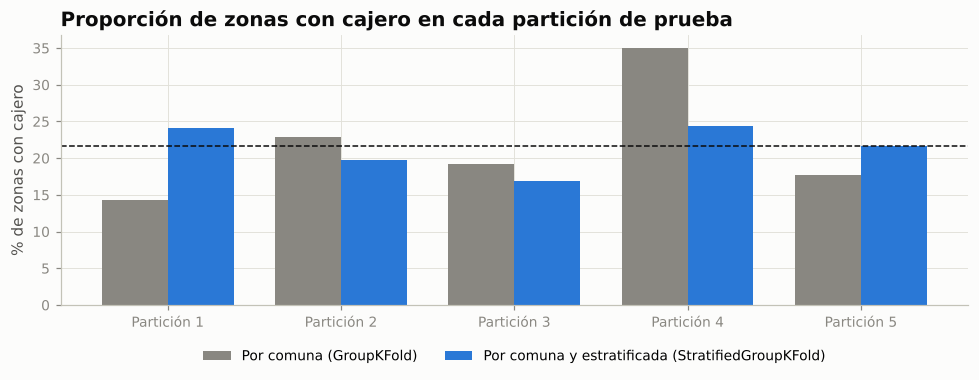

,modelo,AUC por comuna,desvío por comuna,AUC estratificada,desvío estratificada
0,Regresión logística,0.83,0.05,0.83,0.06
1,Árbol de decisión,0.80,0.06,0.80,0.05
2,Random Forest,0.83,0.06,0.83,0.05
3,XGBoost,0.83,0.06,0.82,0.06


In [3]:
p = T["particiones"]
tabla_p = p.pivot(index="partición", columns="validación", values="con cajero (%)")
fig, ax = plt.subplots(figsize=(9, 3.6))
ancho = 0.38
xs = np.arange(len(tabla_p))
for i, (col, color) in enumerate(zip(tabla_p.columns, [e.TINTA_SUAVE, e.LINK])):
    ax.bar(xs + (i - 0.5) * ancho, tabla_p[col], width=ancho, color=color, label=col)
ax.axhline(100 * res.loc[mascara, "term_total"].gt(0).mean(), color=e.TINTA, linewidth=1, linestyle="--")
ax.set_xticks(xs, [f"Partición {k}" for k in tabla_p.index])
ax.set(ylabel="% de zonas con cajero", title="Proporción de zonas con cajero en cada partición de prueba")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2, frameon=False)
e.ejes_es(ax, y=0); fig.tight_layout(); fig.savefig(FIG / "tec_estratificada.png"); plt.show()
T["estratificada"].round(3)

**Lectura.** Por comuna sola, la proporción de zonas con cajero en cada partición de prueba va de 14 % a 35 %; estratificada, de 17 % a 24 %. Con particiones más parejas, **Random Forest** sigue siendo el mejor clasificador y su AUC casi no cambia (0,83 por comuna, 0,83 estratificada): la conclusión del notebook 02 no dependía de cómo cayeron las clases en cada partición.

## 3. PCA: cuánta información comparten las variables

PCA reemplaza las variables originales por **componentes principales**: combinaciones de ellas, sin correlación entre sí y
ordenadas por la varianza que explican. Lo usamos para **entender** la estructura de las 14 variables de demanda, no como
entrada de los modelos. Las variables entran como en la regresión: conteos en logaritmo y todo estandarizado (PCA, como
K-Means, es sensible a la escala).

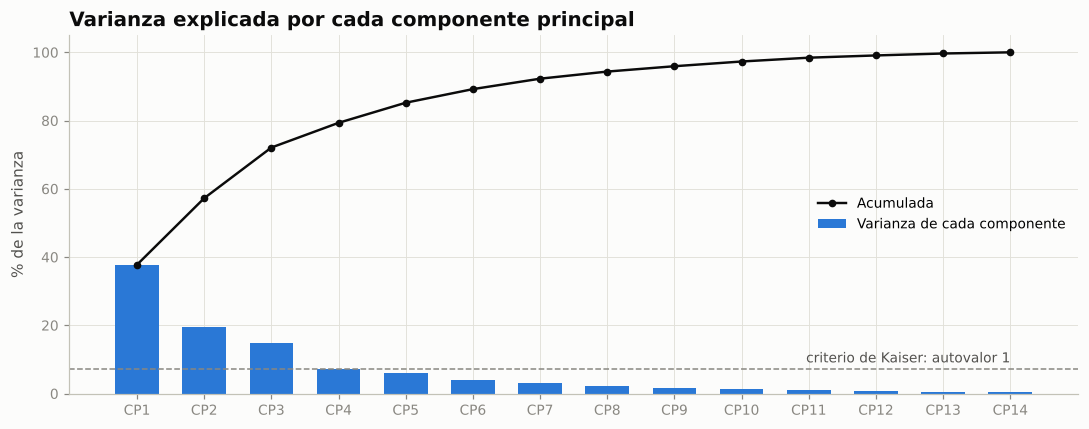

Kaiser: 4 componentes · 80 %: 5 · 95 %: 9


,componente,varianza (%),acumulada (%),autovalor
0,CP1,37.76,37.76,5.29
1,CP2,19.49,57.25,2.73
2,CP3,14.84,72.10,2.08
3,CP4,7.24,79.34,1.01
4,CP5,5.89,85.23,0.83
5,CP6,3.99,89.21,0.56


In [4]:
v = T["pca"]["varianza"]
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(v["componente"], v["varianza (%)"], color=e.LINK, width=0.65, label="Varianza de cada componente")
ax.plot(v["componente"], v["acumulada (%)"], color=e.TINTA, marker="o", markersize=4, linewidth=1.6, label="Acumulada")
ax.axhline(100 / len(v), color=e.TINTA_SUAVE, linestyle="--", linewidth=1)
ax.text(len(v) - 1, 100 / len(v) + 2, "criterio de Kaiser: autovalor 1", ha="right", fontsize=9, color=e.TINTA_2)
ax.set(ylabel="% de la varianza", title="Varianza explicada por cada componente principal", ylim=(0, 105))
ax.legend(loc="center right"); e.ejes_es(ax, y=0)
fig.tight_layout(); fig.savefig(FIG / "tec_pca_varianza.png"); plt.show()
print(f"Kaiser: {T['pca']['kaiser']} componentes · 80 %: {T['pca']['n_80']} · 95 %: {T['pca']['n_95']}")
v.head(6).round(2)

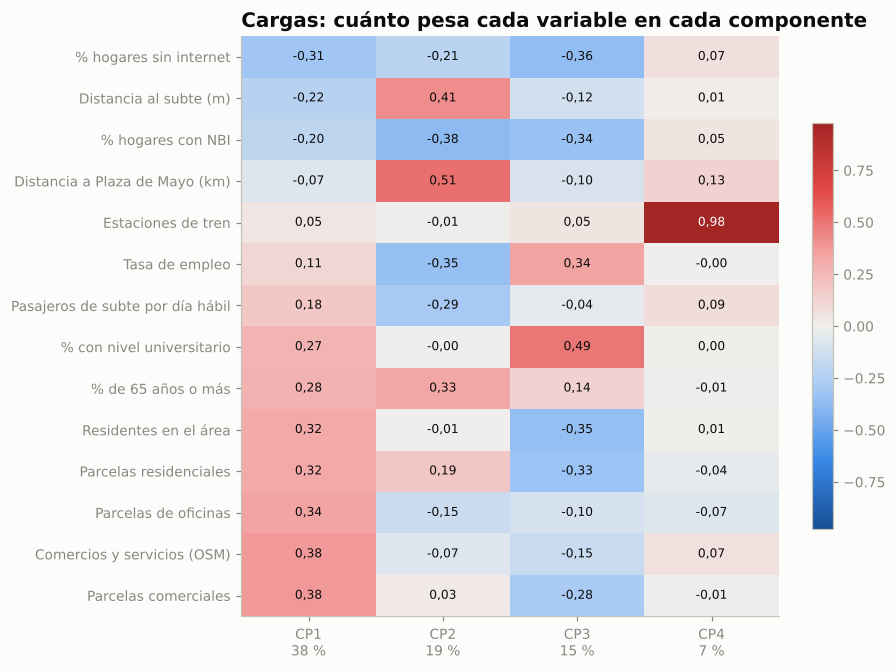

In [5]:
cargas = T["pca"]["cargas"].set_index("nombre").drop(columns="variable")
orden = cargas["CP1"].sort_values().index
fig, ax = plt.subplots(figsize=(8.5, 6.2))
lim = float(np.abs(cargas.values).max())
im = ax.imshow(cargas.loc[orden].values, cmap=e.cmap_divergente(), vmin=-lim, vmax=lim, aspect="auto")
ax.set_xticks(range(cargas.shape[1]), [f"{c}\n{e.num_es(x)} %" for c, x in zip(cargas.columns, v["varianza (%)"])])
ax.set_yticks(range(len(orden)), orden)
for i, nombre in enumerate(orden):
    for j, c in enumerate(cargas.columns):
        val = cargas.loc[nombre, c]
        ax.text(j, i, e.num_es(val, 2), ha="center", va="center", fontsize=8,
                color="white" if abs(val) > 0.6 * lim else e.TINTA)
ax.set_title("Cargas: cuánto pesa cada variable en cada componente")
ax.grid(False); fig.colorbar(im, ax=ax, shrink=0.7)
fig.tight_layout(); fig.savefig(FIG / "tec_pca_cargas.png"); plt.show()

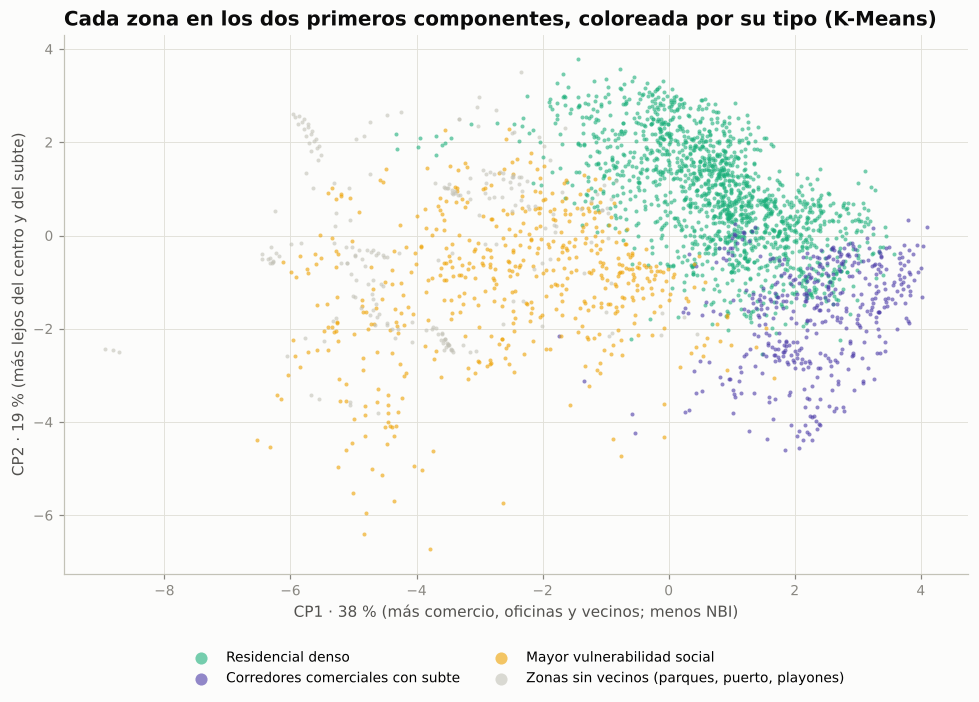

,componentes,varianza retenida (%),ARI contra los tipos de zona,silueta
0,2,65.45,0.51,0.40
1,3,80.98,0.66,0.39
2,4,89.49,0.99,0.41
3,7,100.00,1.00,0.36


In [6]:
pts = T["pca"]["puntajes"]
fig, ax = plt.subplots(figsize=(9, 6.5))
for z in sorted(pts["tipo_zona"].dropna().unique(), key=lambda z: z.startswith("Zonas sin")):
    d = pts[pts["tipo_zona"] == z]
    ax.scatter(d["CP1"], d["CP2"], s=7, alpha=0.6, color=e.color_zona(z), label=z, linewidth=0)
ax.set(xlabel=f"CP1 · {e.num_es(v['varianza (%)'].iloc[0])} % (más comercio, oficinas y vecinos; menos NBI)",
       ylabel=f"CP2 · {e.num_es(v['varianza (%)'].iloc[1])} % (más lejos del centro y del subte)",
       title="Cada zona en los dos primeros componentes, coloreada por su tipo (K-Means)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2, frameon=False, markerscale=3)
e.ejes_es(ax); fig.tight_layout(); fig.savefig(FIG / "tec_pca_zonas.png"); plt.show()
T["zonas_pca"].round(3)

**Lectura.** Dos componentes guardan el 57 % de la información de las 14 variables y cuatro, el 79 %. El criterio de Kaiser (autovalor mayor a 1) también se queda con 4; para llegar al 95 % harían falta 9. Repetido sobre cuatro componentes (que retienen el 89 % de la varianza de sus variables), el K-Means arma prácticamente los mismos tipos de zona: índice de Rand ajustado de 0,99 (1 sería idéntico).

- **CP1, intensidad urbana:** sube con el comercio, las oficinas, los vecinos y el nivel universitario, y baja con los
  hogares sin internet o con NBI y con la distancia al subte. Es el eje que separa los corredores comerciales del resto.
- **CP2, lejanía del centro:** sube con la distancia al centro y al subte y con los mayores de 65 (barrios residenciales del
  oeste y del norte), y baja con el NBI, la tasa de empleo y los pasajeros de subte.
- **Variables que dicen casi lo mismo:** comercios de OpenStreetMap y parcelas comerciales tienen correlación 0,84; hogares
  con NBI y sin internet, 0,78. PCA las junta en el mismo eje.

**Por qué no lo usamos como entrada de los modelos.** Son solo 14 variables, los árboles no lo necesitan y perderíamos lo
que más le sirve a la gerencia: explicar cada zona con variables que se entienden (los valores SHAP del notebook 02). Si un
modelo dijera "le faltan cajeros porque el CP1 es alto", habría que traducirlo de vuelta.

## 4. K-Means para ubicar cajeros, como se propuso en la clase

En la clase se planteó que, con un número fijo de cajeros, K-Means sirve para ubicarlos: cada centro de grupo es un cajero.
Lo probamos con la gente que hoy no tiene un Link a 500 m, pesando cada hexágono por sus vecinos, y llevamos cada centro al
sitio con comercio más cercano. Lo comparamos con nuestra **optimización exacta** (cobertura máxima, notebook 03), que
elige los sitios que más vecinos dejan a 500 m.

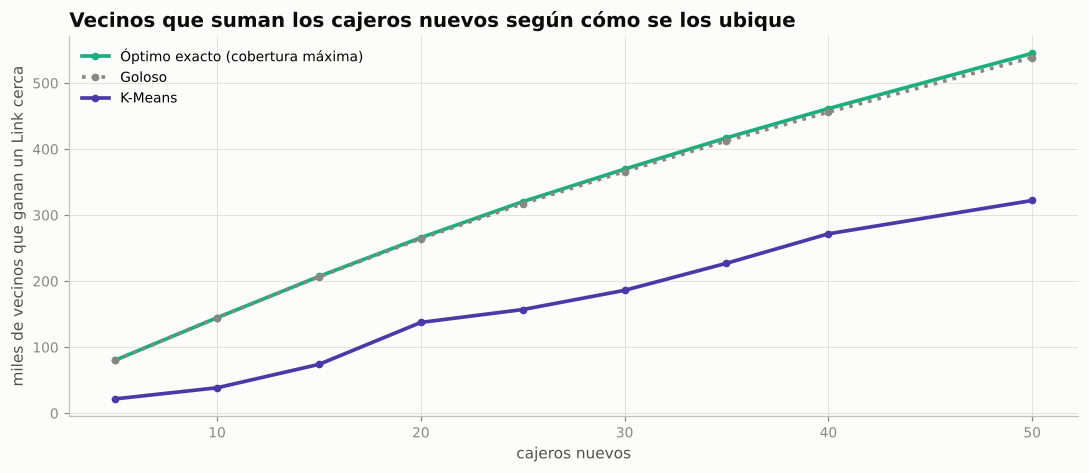

,cajeros,óptimo exacto,goloso,K-Means,K-Means / óptimo (%),distancia media hoy (m),distancia media con el óptimo (m),distancia media con K-Means (m),sitios en común
0,5,"80,292.30","80,292.30","21,717.70",27.00,818.30,785.10,808.70,0
1,10,"144,615.60","144,615.60","38,536.00",26.60,818.30,749.90,800.70,0
2,15,"207,154.70","206,634.30","73,972.30",35.70,818.30,730.40,776.00,1
3,20,"265,928.90","264,384.30","137,505.60",51.70,818.30,707.20,733.80,2
4,25,"320,354.60","317,269.20","156,992.40",49.00,818.30,697.90,717.50,1
5,30,"369,671.00","366,022.40","186,104.00",50.30,818.30,671.50,700.50,1
6,35,"417,058.90","412,473.20","227,069.30",54.40,818.30,654.80,679.80,2
7,40,"461,346.80","455,948.40","271,681.20",58.90,818.30,639.70,665.00,2
8,50,"544,973.00","538,631.20","322,169.90",59.10,818.30,613.90,642.10,2


In [7]:
km = T["kmeans"]
fig, ax = plt.subplots(figsize=(10, 4.4))
for col, color, est, nombre in [("óptimo exacto", e.SUGERIDO, "-", "Óptimo exacto (cobertura máxima)"),
                                ("goloso", e.TINTA_SUAVE, ":", "Goloso"), ("K-Means", "#4a3aa7", "-", "K-Means")]:
    ax.plot(km["cajeros"], km[col] / 1e3, color=color, linestyle=est, linewidth=2.4, marker="o", markersize=4, label=nombre)
ax.set(xlabel="cajeros nuevos", ylabel="miles de vecinos que ganan un Link cerca",
       title="Vecinos que suman los cajeros nuevos según cómo se los ubique")
ax.legend(loc="upper left"); e.ejes_es(ax, y=0)
fig.tight_layout(); fig.savefig(FIG / "tec_kmeans_curva.png"); plt.show()
km.round(1)

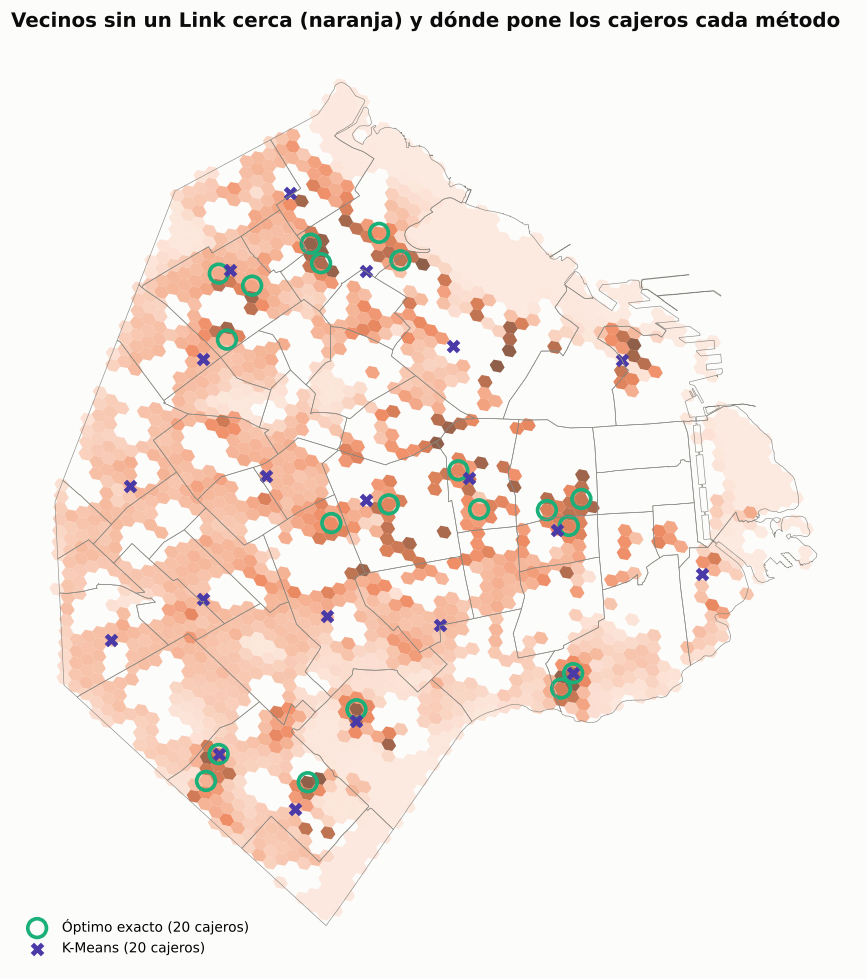

In [8]:
s20 = T["sitios_20"]
col = conj["columna_distancia"]
fig, ax = plt.subplots(figsize=(10, 9))
barrios.boundary.plot(ax=ax, color=e.TINTA_SUAVE, linewidth=0.4)
sin = res[(res[col] > tec.RADIO_M) & (res["poblacion"] > 0)]
gpd.GeoDataFrame(sin, geometry=[f.poligono_hex(h) for h in sin["h3"]], crs="EPSG:4326").plot(
    ax=ax, column="poblacion", cmap=e.cmap_secuencial(e.SECUENCIAL_NARANJA), linewidth=0, alpha=0.75,
    vmax=res["poblacion"].quantile(0.98))
ax.scatter(s20["exacto"]["lon"], s20["exacto"]["lat"], s=150, facecolor="none", edgecolor=e.SUGERIDO, linewidth=2.4,
           label="Óptimo exacto (20 cajeros)")
ax.scatter(s20["kmeans"]["lon"], s20["kmeans"]["lat"], s=80, marker="X", color="#4a3aa7", linewidth=0,
           label="K-Means (20 cajeros)")
ax.legend(loc="lower left"); ax.set_axis_off()
ax.set_title("Vecinos sin un Link cerca (naranja) y dónde pone los cajeros cada método")
fig.tight_layout(); fig.savefig(FIG / "tec_kmeans_mapa.png"); plt.show()

**Lectura.** Con 20 cajeros, K-Means suma **137.506 vecinos** con un Link a 500 m caminando; el óptimo exacto, **265.929**: K-Means llega al 52 % del óptimo (entre el 27 % y el 59 % según la cantidad de cajeros), y solo 2 de los 20 sitios coinciden. Tampoco gana en distancia: la distancia media de la gente sin Link al Link más cercano baja de 818 m a 734 m con K-Means y a 707 m con el óptimo.

**Por qué pasa.** K-Means minimiza la distancia al cuadrado de cada persona al centro de su grupo, y para eso no sabe dos
cosas: dónde están los cajeros que ya existen (reparte los 20 como si la ciudad estuviera vacía) y que el objetivo de negocio
es que la gente quede **a 5 cuadras**. Con pocos grupos, cada centro cae en el medio de una región enorme y le quedan cerca
pocas personas. La optimización exacta resuelve el problema que de verdad tiene la gerencia. K-Means sigue siendo útil para
lo que hace bien: describir, como en los tipos de zona (notebook 03).

## 5. DBSCAN: bolsones de vecinos sin un Link cerca

K-Means obliga a elegir cuántos grupos hay y supone grupos redondos. **DBSCAN** busca zonas **densas**: un grupo es una zona
donde los puntos están juntos, separada de otras por zonas vacías, y lo que queda aislado es **ruido**. Lo aplicamos a los
hexágonos con vecinos sin un Link a distancia caminable, pesados por su gente:

- `eps` = 320 m: dos hexágonos son vecinos si sus centros están a menos de esa distancia (los contiguos están a unos 300 m);
- mínimo = 8.000 vecinos sin Link entre un hexágono y los de al lado. Como referencia, cada uno de los 20 cajeros óptimos
  suma unos 13 mil.

In [9]:
T["sensibilidad"].round(1)

,mínimo de vecinos,bolsones,vecinos sin Link en bolsones (%),el más grande
0,6000,29,81.60,"243,525.50"
1,8000,32,55.90,"60,568.70"
2,10000,21,34.50,"47,414.80"


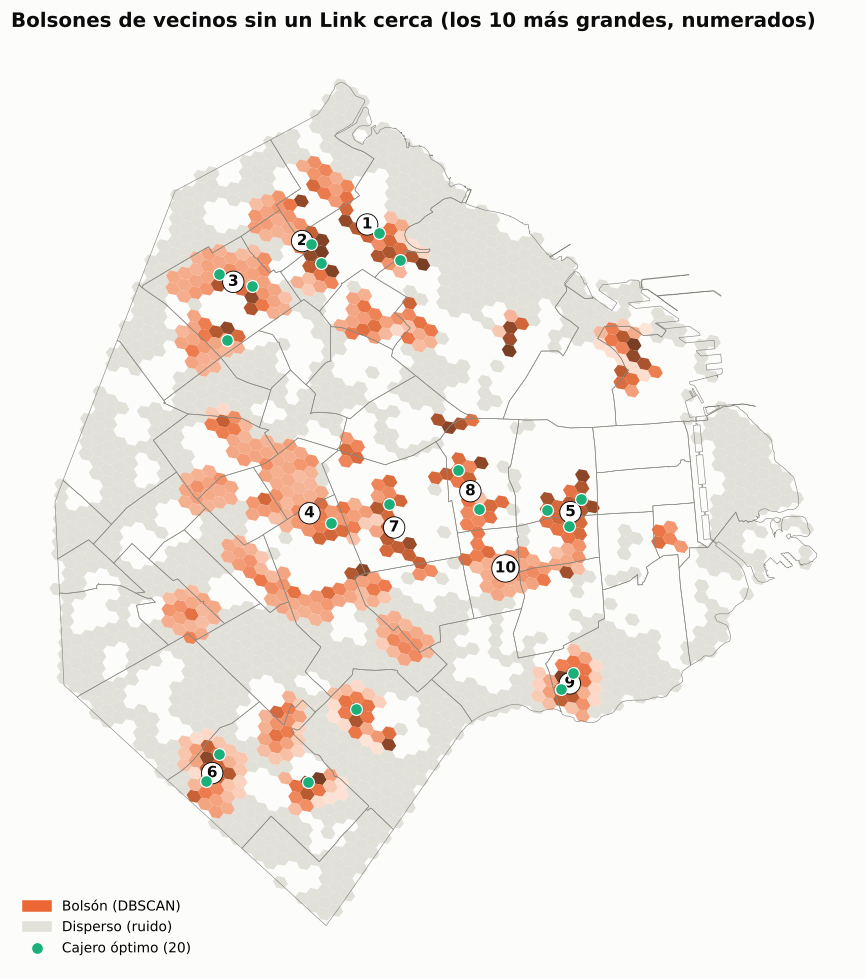

,bolsón,vecinos sin Link,hexágonos,barrios,le toca un cajero óptimo
0,1,"60,569.00",34,"Belgrano, Núñez y Palermo",True
1,2,"59,377.00",33,"Belgrano, Coghlan y Núñez",True
2,3,"55,617.00",40,Villa Urquiza y Coghlan,True
3,4,"51,217.00",36,"Flores, Villa General Mitre y Villa Santa Rita",True
4,5,"48,873.00",21,Balvanera y San Cristóbal,True
5,6,"42,102.00",33,Villa Lugano y Mataderos,True
6,7,"41,144.00",21,Caballito y Parque Chacabuco,True
7,8,"38,432.00",19,"Almagro, Caballito y Boedo",True
8,9,"38,364.00",26,Barracas y Nueva Pompeya,True
9,10,"34,099.00",25,"Boedo, Parque Patricios y San Cristóbal",False


In [10]:
etiq = T["etiquetas"]
b = T["bolsones"]
d = res.assign(bolson=etiq)[etiq.notna()]
fig, ax = plt.subplots(figsize=(10, 9))
barrios.boundary.plot(ax=ax, color=e.TINTA_SUAVE, linewidth=0.4)
ruido = d[d["bolson"] < 0]
gpd.GeoDataFrame(ruido, geometry=[f.poligono_hex(h) for h in ruido["h3"]], crs="EPSG:4326").plot(
    ax=ax, color=e.GRILLA, linewidth=0, label="Disperso (ruido)")
enb = d[d["bolson"] > 0]
gpd.GeoDataFrame(enb, geometry=[f.poligono_hex(h) for h in enb["h3"]], crs="EPSG:4326").plot(
    ax=ax, column="poblacion", cmap=e.cmap_secuencial(e.SECUENCIAL_NARANJA), linewidth=0, alpha=0.9,
    vmin=0, vmax=res["poblacion"].quantile(0.98))
for _, r in b.head(10).iterrows():
    ax.text(r["lon"], r["lat"], str(int(r["bolsón"])), fontsize=10, fontweight="bold", ha="center", va="center",
            color=e.TINTA, bbox=dict(boxstyle="circle,pad=0.2", fc="white", ec=e.TINTA, lw=0.6))
ex = T["sitios_20"]["exacto"]
ax.scatter(ex["lon"], ex["lat"], s=60, color=e.SUGERIDO, edgecolor="white", linewidth=0.8, zorder=4,
           label="Cajero óptimo (20)")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=e.SECUENCIAL_NARANJA[3], label="Bolsón (DBSCAN)"), Patch(color=e.GRILLA, label="Disperso (ruido)"),
                   plt.Line2D([], [], marker="o", linestyle="", color=e.SUGERIDO, label="Cajero óptimo (20)")],
          loc="lower left")
ax.set_axis_off(); ax.set_title("Bolsones de vecinos sin un Link cerca (los 10 más grandes, numerados)")
fig.tight_layout(); fig.savefig(FIG / "tec_dbscan_mapa.png"); plt.show()
b.head(10)[["bolsón", "vecinos sin Link", "hexágonos", "barrios", "le toca un cajero óptimo"]].round(0)

**Lectura.** DBSCAN encuentra **32 bolsones** de vecinos sin un Link a distancia caminable: juntan 843.113 personas, el 56 % de las 1.507.883 que no tienen uno cerca. El más grande está en Belgrano, Núñez y Palermo (60.569 vecinos). Los 20 cajeros óptimos caen en 12 bolsones distintos: los otros 20 son la lista para una segunda tanda.

Para la Gerencia Comercial, los bolsones son una forma de presentar la expansión por áreas y no por puntos sueltos: cada
bolsón es una zona continua con mucha gente sin un Link a 5 cuadras. La gente que queda **dispersa** también existe, pero un
cajero ahí suma pocos vecinos; para esas zonas sirven más otros canales (corresponsales, comercios con extracción).

## 6. Conclusión

- **Técnica:** el escalado ya estaba adentro de cada pipeline, sin fuga de datos. Con validación estratificada por grupos el
  clasificador elegido no cambia. PCA muestra que cuatro componentes resumen la mayor parte de la información y que los tipos
  de zona no dependen de cómo se midan las variables. Para ubicar cajeros, K-Means queda lejos de la optimización exacta,
  porque optimiza otra cosa; DBSCAN encuentra dónde se concentra la gente sin cobertura.
- **Negocio:** la recomendación no cambia y queda más firme: los 20 sitios de la optimización exacta suman casi el doble de
  vecinos que ubicarlos con K-Means, y caen en los bolsones más densos de gente sin un Link cerca. Los bolsones que quedan
  sin cajero son la lista para la siguiente tanda.